<a href="https://colab.research.google.com/github/sabitabir/CVPR/blob/main/CNN_23_53234_3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip install -q kagglehub torchinfo

In [2]:
import os, random, time
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image

import torch
import torch.nn as nn
from torch.utils.data import DataLoader, Subset, random_split
from torchvision import datasets, transforms
from torchinfo import summary

import kagglehub
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

# ---------- Reproducibility ----------
SEED = 42
def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False
set_seed()

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"PyTorch {torch.__version__} | Device: {device}")
if device.type == "cpu":
    print("WARNING: GPU not detected - training will be slow. Enable GPU in Colab runtime settings.")

PyTorch 2.14.1+cu130 | Device: cuda


In [3]:
path = kagglehub.dataset_download("puneet6060/intel-image-classification")
print("Dataset path:", path)

TRAIN_DIR = os.path.join(path, "seg_train", "seg_train")
TEST_DIR  = os.path.join(path, "seg_test",  "seg_test")
assert os.path.isdir(TRAIN_DIR) and os.path.isdir(TEST_DIR), "Unexpected folder structure - check the dataset path."

CLASSES = sorted(os.listdir(TRAIN_DIR))
print("Classes:", CLASSES)

def count_images(root):
    return {c: len(os.listdir(os.path.join(root, c))) for c in sorted(os.listdir(root))}

train_counts, test_counts = count_images(TRAIN_DIR), count_images(TEST_DIR)
counts_df = pd.DataFrame({"train": train_counts, "test": test_counts})
counts_df.loc["TOTAL"] = counts_df.sum()
print(counts_df)

Using Colab cache for faster access to the 'intel-image-classification' dataset.
Dataset path: /kaggle/input/intel-image-classification
Classes: ['buildings', 'forest', 'glacier', 'mountain', 'sea', 'street']
           train  test
buildings   2191   437
forest      2271   474
glacier     2404   553
mountain    2512   525
sea         2274   510
street      2382   501
TOTAL      14034  3000


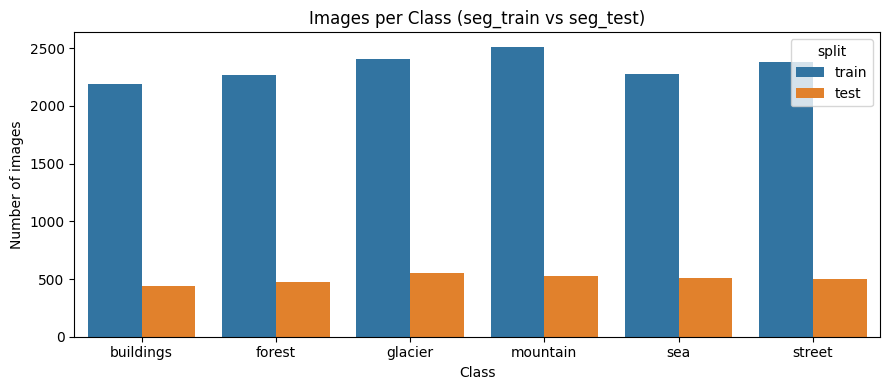

Most common sizes in a 500-image sample (W, H): [((150, 150), 499), ((150, 97), 1)]


In [4]:
# ---------- Class distribution bar chart ----------
plot_df = counts_df.drop("TOTAL").reset_index().melt(id_vars="index", var_name="split", value_name="images")
plt.figure(figsize=(9, 4))
sns.barplot(data=plot_df, x="index", y="images", hue="split")
plt.title("Images per Class (seg_train vs seg_test)")
plt.xlabel("Class"); plt.ylabel("Number of images")
plt.tight_layout(); plt.show()

# ---------- Image size variety (sampled) ----------
rng = random.Random(SEED)
all_paths = [os.path.join(TRAIN_DIR, c, f) for c in CLASSES for f in os.listdir(os.path.join(TRAIN_DIR, c))]
sizes = Counter(Image.open(p).size for p in rng.sample(all_paths, 500))
print("Most common sizes in a 500-image sample (W, H):", sizes.most_common(5))

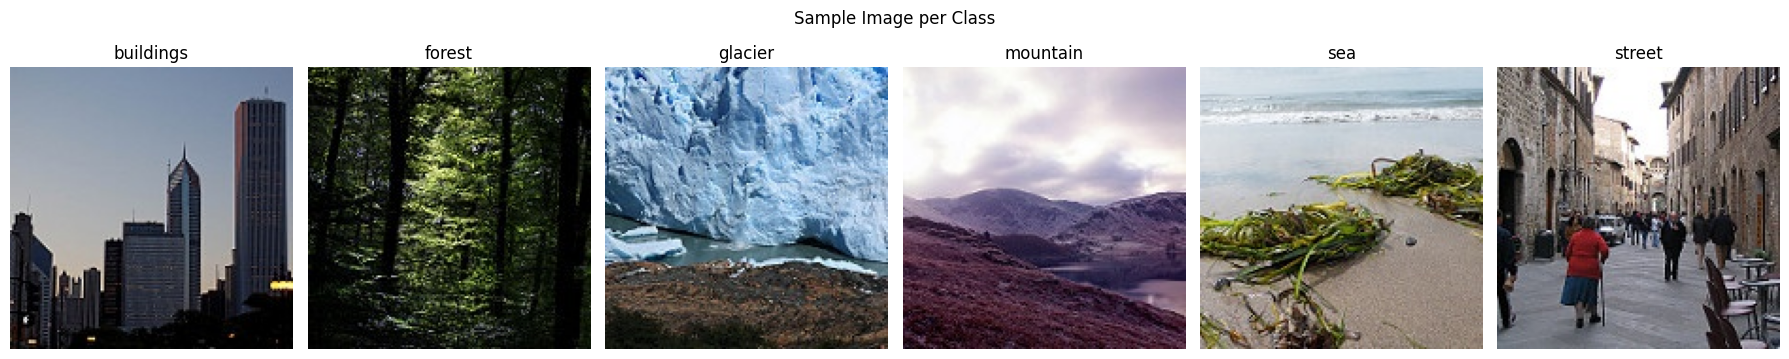

In [5]:
# ---------- 6-class sample grid (one random image per class) ----------
fig, axes = plt.subplots(1, 6, figsize=(18, 3.5))
for ax, cls in zip(axes, CLASSES):
    fname = rng.choice(os.listdir(os.path.join(TRAIN_DIR, cls)))
    ax.imshow(Image.open(os.path.join(TRAIN_DIR, cls, fname)))
    ax.set_title(cls); ax.axis("off")
plt.suptitle("Sample Image per Class", y=1.02)
plt.tight_layout(); plt.show()

In [6]:
IMG_SIZE   = 128
BATCH_SIZE = 64
MEAN, STD  = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]

train_tf = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomHorizontalFlip(p=0.5),                 # no vertical flip: scenes are upright
    transforms.RandomRotation(15),
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])
eval_tf = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])

# Two views of the same folder: one with augmentation (train), one without (val).
full_train_aug  = datasets.ImageFolder(TRAIN_DIR, transform=train_tf)
full_train_eval = datasets.ImageFolder(TRAIN_DIR, transform=eval_tf)
test_ds         = datasets.ImageFolder(TEST_DIR,  transform=eval_tf)
assert full_train_aug.class_to_idx == test_ds.class_to_idx, "Class order mismatch between train and test!"

# 80/20 split with a seeded generator (same indices -> no leakage between train and val)
n_total = len(full_train_aug)
n_train = int(0.8 * n_total)
n_val   = n_total - n_train
split_gen = torch.Generator().manual_seed(SEED)
train_idx, val_idx = [s.indices for s in random_split(range(n_total), [n_train, n_val], generator=split_gen)]

train_ds = Subset(full_train_aug,  train_idx)   # augmented
val_ds   = Subset(full_train_eval, val_idx)     # clean

loader_kw = dict(batch_size=BATCH_SIZE, num_workers=2, pin_memory=(device.type == "cuda"))
train_loader = DataLoader(train_ds, shuffle=True, generator=torch.Generator().manual_seed(SEED), **loader_kw)
val_loader   = DataLoader(val_ds,   shuffle=False, **loader_kw)
test_loader  = DataLoader(test_ds,  shuffle=False, **loader_kw)

print(f"Train: {len(train_ds)} | Val: {len(val_ds)} | Test: {len(test_ds)}")
print(f"Batches/epoch -> train: {len(train_loader)}, val: {len(val_loader)}, test: {len(test_loader)}")
print("Class mapping:", full_train_aug.class_to_idx)

Train: 11227 | Val: 2807 | Test: 3000
Batches/epoch -> train: 176, val: 44, test: 47
Class mapping: {'buildings': 0, 'forest': 1, 'glacier': 2, 'mountain': 3, 'sea': 4, 'street': 5}


In [7]:
def conv_block(in_ch, out_ch):
    """Conv-BN-ReLU twice, then 2x2 max-pooling."""
    return nn.Sequential(
        nn.Conv2d(in_ch,  out_ch, kernel_size=3, padding=1, bias=False),
        nn.BatchNorm2d(out_ch), nn.ReLU(inplace=True),
        nn.Conv2d(out_ch, out_ch, kernel_size=3, padding=1, bias=False),
        nn.BatchNorm2d(out_ch), nn.ReLU(inplace=True),
        nn.MaxPool2d(2),
    )

class IntelCNN(nn.Module):
    def __init__(self, num_classes=6, dropout=0.3):
        super().__init__()
        self.features = nn.Sequential(
            conv_block(3,   32),    # 128 -> 64
            conv_block(32,  64),    # 64  -> 32
            conv_block(64,  128),   # 32  -> 16
            conv_block(128, 256),   # 16  -> 8
        )
        self.pool = nn.AdaptiveAvgPool2d((1, 1))    # 256 x 8 x 8 -> 256 x 1 x 1
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Dropout(dropout),
            nn.Linear(256, num_classes),
        )

    def forward(self, x):
        return self.classifier(self.pool(self.features(x)))

set_seed()                                   # same init every run
model = IntelCNN(num_classes=len(CLASSES)).to(device)
summary(model, input_size=(BATCH_SIZE, 3, IMG_SIZE, IMG_SIZE),
        col_names=("input_size", "output_size", "num_params"), depth=2)

Layer (type:depth-idx)                   Input Shape               Output Shape              Param #
IntelCNN                                 [64, 3, 128, 128]         [64, 6]                   --
├─Sequential: 1-1                        [64, 3, 128, 128]         [64, 256, 8, 8]           --
│    └─Sequential: 2-1                   [64, 3, 128, 128]         [64, 32, 64, 64]          10,208
│    └─Sequential: 2-2                   [64, 32, 64, 64]          [64, 64, 32, 32]          55,552
│    └─Sequential: 2-3                   [64, 64, 32, 32]          [64, 128, 16, 16]         221,696
│    └─Sequential: 2-4                   [64, 128, 16, 16]         [64, 256, 8, 8]           885,760
├─AdaptiveAvgPool2d: 1-2                 [64, 256, 8, 8]           [64, 256, 1, 1]           --
├─Sequential: 1-3                        [64, 256, 1, 1]           [64, 6]                   --
│    └─Flatten: 2-5                      [64, 256, 1, 1]           [64, 256]                 --
│    └─Dropout: 2

In [8]:
EPOCHS, LR = 20, 1e-3
CKPT_PATH = "best_cnn_intel.pth"

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=LR)

def run_epoch(model, loader, optimizer=None):
    """One pass over `loader`. Trains if an optimizer is given, otherwise evaluates."""
    training = optimizer is not None
    model.train(training)
    total_loss, correct, n = 0.0, 0, 0
    with torch.set_grad_enabled(training):
        for x, y in loader:
            x, y = x.to(device, non_blocking=True), y.to(device, non_blocking=True)
            logits = model(x)
            loss = criterion(logits, y)
            if training:
                optimizer.zero_grad(set_to_none=True)
                loss.backward()
                optimizer.step()
            total_loss += loss.item() * x.size(0)
            correct    += (logits.argmax(1) == y).sum().item()
            n          += x.size(0)
    return total_loss / n, correct / n

history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}
best_val_acc, best_epoch = 0.0, 0
start = time.time()

for epoch in range(1, EPOCHS + 1):
    tr_loss, tr_acc = run_epoch(model, train_loader, optimizer)
    va_loss, va_acc = run_epoch(model, val_loader)

    for k, v in zip(history, (tr_loss, va_loss, tr_acc, va_acc)):
        history[k].append(v)

    saved = ""
    if va_acc > best_val_acc:
        best_val_acc, best_epoch = va_acc, epoch
        torch.save(model.state_dict(), CKPT_PATH)
        saved = "  <-- saved best"
    print(f"Epoch {epoch:02d}/{EPOCHS} | train loss {tr_loss:.4f} acc {tr_acc:.4f} | "
          f"val loss {va_loss:.4f} acc {va_acc:.4f}{saved}")

print(f"\nDone in {(time.time()-start)/60:.1f} min | best val acc {best_val_acc:.4f} at epoch {best_epoch}")

Epoch 01/20 | train loss 0.9517 acc 0.6308 | val loss 0.8625 acc 0.6605  <-- saved best
Epoch 02/20 | train loss 0.6625 acc 0.7560 | val loss 0.6459 acc 0.7567  <-- saved best
Epoch 03/20 | train loss 0.5661 acc 0.7947 | val loss 0.5349 acc 0.8130  <-- saved best
Epoch 04/20 | train loss 0.5261 acc 0.8120 | val loss 0.5638 acc 0.7998
Epoch 05/20 | train loss 0.4857 acc 0.8240 | val loss 0.4103 acc 0.8479  <-- saved best
Epoch 06/20 | train loss 0.4624 acc 0.8330 | val loss 0.5739 acc 0.8076
Epoch 07/20 | train loss 0.4229 acc 0.8491 | val loss 0.5464 acc 0.8147
Epoch 08/20 | train loss 0.4021 acc 0.8573 | val loss 0.8364 acc 0.7460
Epoch 09/20 | train loss 0.3876 acc 0.8635 | val loss 0.3605 acc 0.8767  <-- saved best
Epoch 10/20 | train loss 0.3752 acc 0.8641 | val loss 0.3503 acc 0.8803  <-- saved best
Epoch 11/20 | train loss 0.3601 acc 0.8733 | val loss 0.4070 acc 0.8675
Epoch 12/20 | train loss 0.3422 acc 0.8780 | val loss 0.5364 acc 0.8237
Epoch 13/20 | train loss 0.3474 acc 0.87

In [9]:
best_model = IntelCNN(num_classes=len(CLASSES)).to(device)
best_model.load_state_dict(torch.load(CKPT_PATH, map_location=device))
best_model.eval()

@torch.no_grad()
def predict(model, loader):
    ys, ps = [], []
    for x, y in loader:
        ps.append(model(x.to(device)).argmax(1).cpu())
        ys.append(y)
    return torch.cat(ys).numpy(), torch.cat(ps).numpy()

y_true, y_pred = predict(best_model, test_loader)
test_acc = accuracy_score(y_true, y_pred)
print(f"Test Accuracy: {test_acc*100:.2f}%\n")
print(classification_report(y_true, y_pred, target_names=test_ds.classes, digits=4))

Test Accuracy: 87.30%

              precision    recall  f1-score   support

   buildings     0.8834    0.8673    0.8753       437
      forest     0.9802    0.9409    0.9602       474
     glacier     0.8219    0.8427    0.8321       553
    mountain     0.8950    0.7467    0.8141       525
         sea     0.8450    0.9196    0.8808       510
      street     0.8399    0.9321    0.8836       501

    accuracy                         0.8730      3000
   macro avg     0.8776    0.8749    0.8744      3000
weighted avg     0.8756    0.8730    0.8724      3000



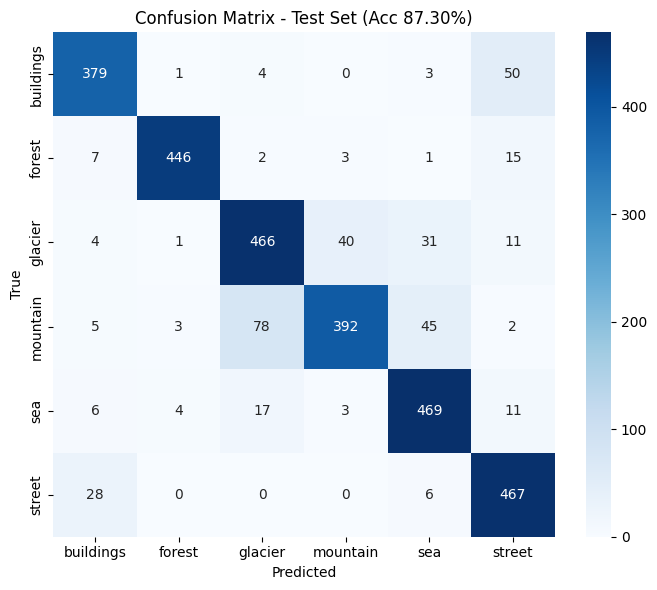

In [10]:
cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(7, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=test_ds.classes, yticklabels=test_ds.classes)
plt.title(f"Confusion Matrix - Test Set (Acc {test_acc*100:.2f}%)")
plt.xlabel("Predicted"); plt.ylabel("True")
plt.tight_layout(); plt.show()

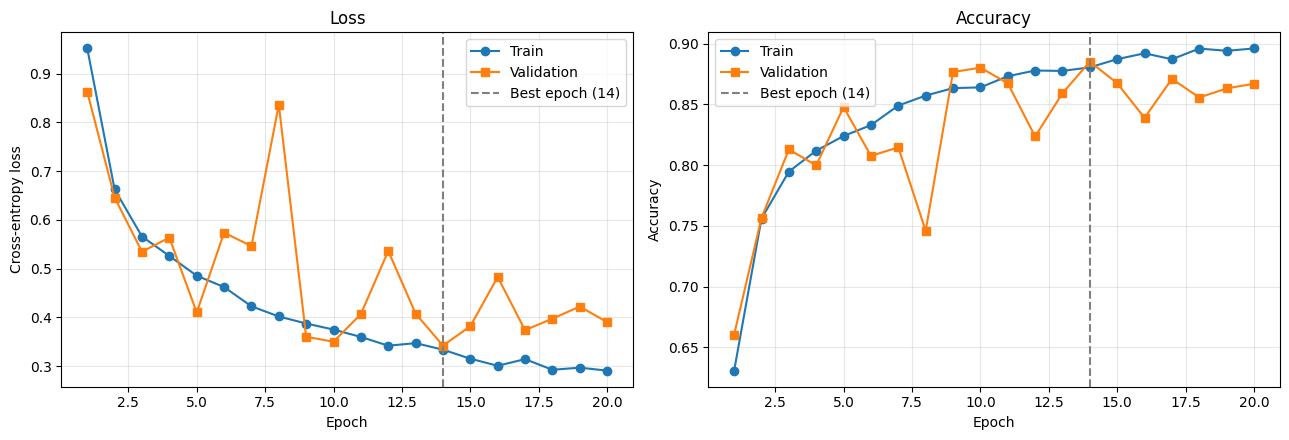

In [11]:
epochs_range = range(1, EPOCHS + 1)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

axes[0].plot(epochs_range, history["train_loss"], "o-", label="Train")
axes[0].plot(epochs_range, history["val_loss"],   "s-", label="Validation")
axes[0].axvline(best_epoch, color="gray", ls="--", label=f"Best epoch ({best_epoch})")
axes[0].set(title="Loss", xlabel="Epoch", ylabel="Cross-entropy loss"); axes[0].legend(); axes[0].grid(alpha=.3)

axes[1].plot(epochs_range, history["train_acc"], "o-", label="Train")
axes[1].plot(epochs_range, history["val_acc"],   "s-", label="Validation")
axes[1].axvline(best_epoch, color="gray", ls="--", label=f"Best epoch ({best_epoch})")
axes[1].set(title="Accuracy", xlabel="Epoch", ylabel="Accuracy"); axes[1].legend(); axes[1].grid(alpha=.3)

plt.tight_layout(); plt.show()

In [12]:
# ---------- Generalisation diagnostics ----------
gap = history["train_acc"][best_epoch-1] - history["val_acc"][best_epoch-1]
print(f"Best epoch: {best_epoch}")
print(f"Train acc @best: {history['train_acc'][best_epoch-1]:.4f} | Val acc @best: {history['val_acc'][best_epoch-1]:.4f} | gap: {gap*100:+.2f} pts")
print(f"Final epoch  -> Train acc {history['train_acc'][-1]:.4f} | Val acc {history['val_acc'][-1]:.4f}")
print(f"Val-loss min at epoch {int(np.argmin(history['val_loss']))+1}; final val loss {history['val_loss'][-1]:.4f}")

if gap > 0.08:
    print("Diagnosis: noticeable OVERFITTING (large train-val gap).")
elif history["val_acc"][-1] < 0.70:
    print("Diagnosis: possible UNDERFITTING (low accuracy).")
else:
    print("Diagnosis: good fit - small train-val gap with solid accuracy.")

# ---------- Most confused class pairs on the test set ----------
errors = [(test_ds.classes[i], test_ds.classes[j], cm[i, j]) for i in range(len(cm)) for j in range(len(cm)) if i != j]
errors.sort(key=lambda t: -t[2])
print("\nTop confusions (true -> predicted):")
for t, p, c in errors[:5]:
    print(f"  {t:>9} -> {p:<9}: {c} images")

# ---------- Model file size check ----------
size_mb = os.path.getsize(CKPT_PATH) / (1024 ** 2)
n_params = sum(p.numel() for p in model.parameters())
print(f"\n{CKPT_PATH}: {size_mb:.2f} MB | parameters: {n_params:,}")
assert size_mb < 20, "Model file exceeds the 20 MB limit!"
print("Size requirement satisfied (< 20 MB).")

Best epoch: 14
Train acc @best: 0.8806 | Val acc @best: 0.8853 | gap: -0.47 pts
Final epoch  -> Train acc 0.8961 | Val acc 0.8671
Val-loss min at epoch 14; final val loss 0.3904
Diagnosis: good fit - small train-val gap with solid accuracy.

Top confusions (true -> predicted):
   mountain -> glacier  : 78 images
  buildings -> street   : 50 images
   mountain -> sea      : 45 images
    glacier -> mountain : 40 images
    glacier -> sea      : 31 images

best_cnn_intel.pth: 4.51 MB | parameters: 1,174,758
Size requirement satisfied (< 20 MB).
